In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [84]:
csv_path = "../data/raw/student-mental-health-6af1a2527d06c522087238.csv"

df = pd.read_csv(csv_path)


In [85]:
df.head()
df.tail()
df.info()
df.describe()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

(2000, 17)

In [86]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percentage': (df.isna().mean() * 100)
})
display(missing.sort_values('missing_count', ascending=False))

,missing_count,missing_percentage
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90
Student_ID,0,0.00
Age,0,0.00
Screen_Time_Hours,0,0.00


In [87]:
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


In [88]:
df.dtypes.value_counts()

float64    8
str        7
int64      2
Name: count, dtype: int64

In [89]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(numerical_columns)
print(categorical_columns)

['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


/tmp/ipykernel_5420/2581685023.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
for col in categorical_columns:
    print(df[col].value_counts(dropna=False))

Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [92]:
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [93]:
df.describe(include="object").T

/tmp/ipykernel_5420/1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


In [94]:
for col in categorical_columns:
    print(df[col].unique())

<StringArray>
['STU0001', 'STU0002', 'STU0003', 'STU0004', 'STU0005', 'STU0006', 'STU0007',
 'STU0008', 'STU0009', 'STU0010',
 ...
 'STU1991', 'STU1992', 'STU1993', 'STU1994', 'STU1995', 'STU1996', 'STU1997',
 'STU1998', 'STU1999', 'STU2000']
Length: 2000, dtype: str
<StringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
<StringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


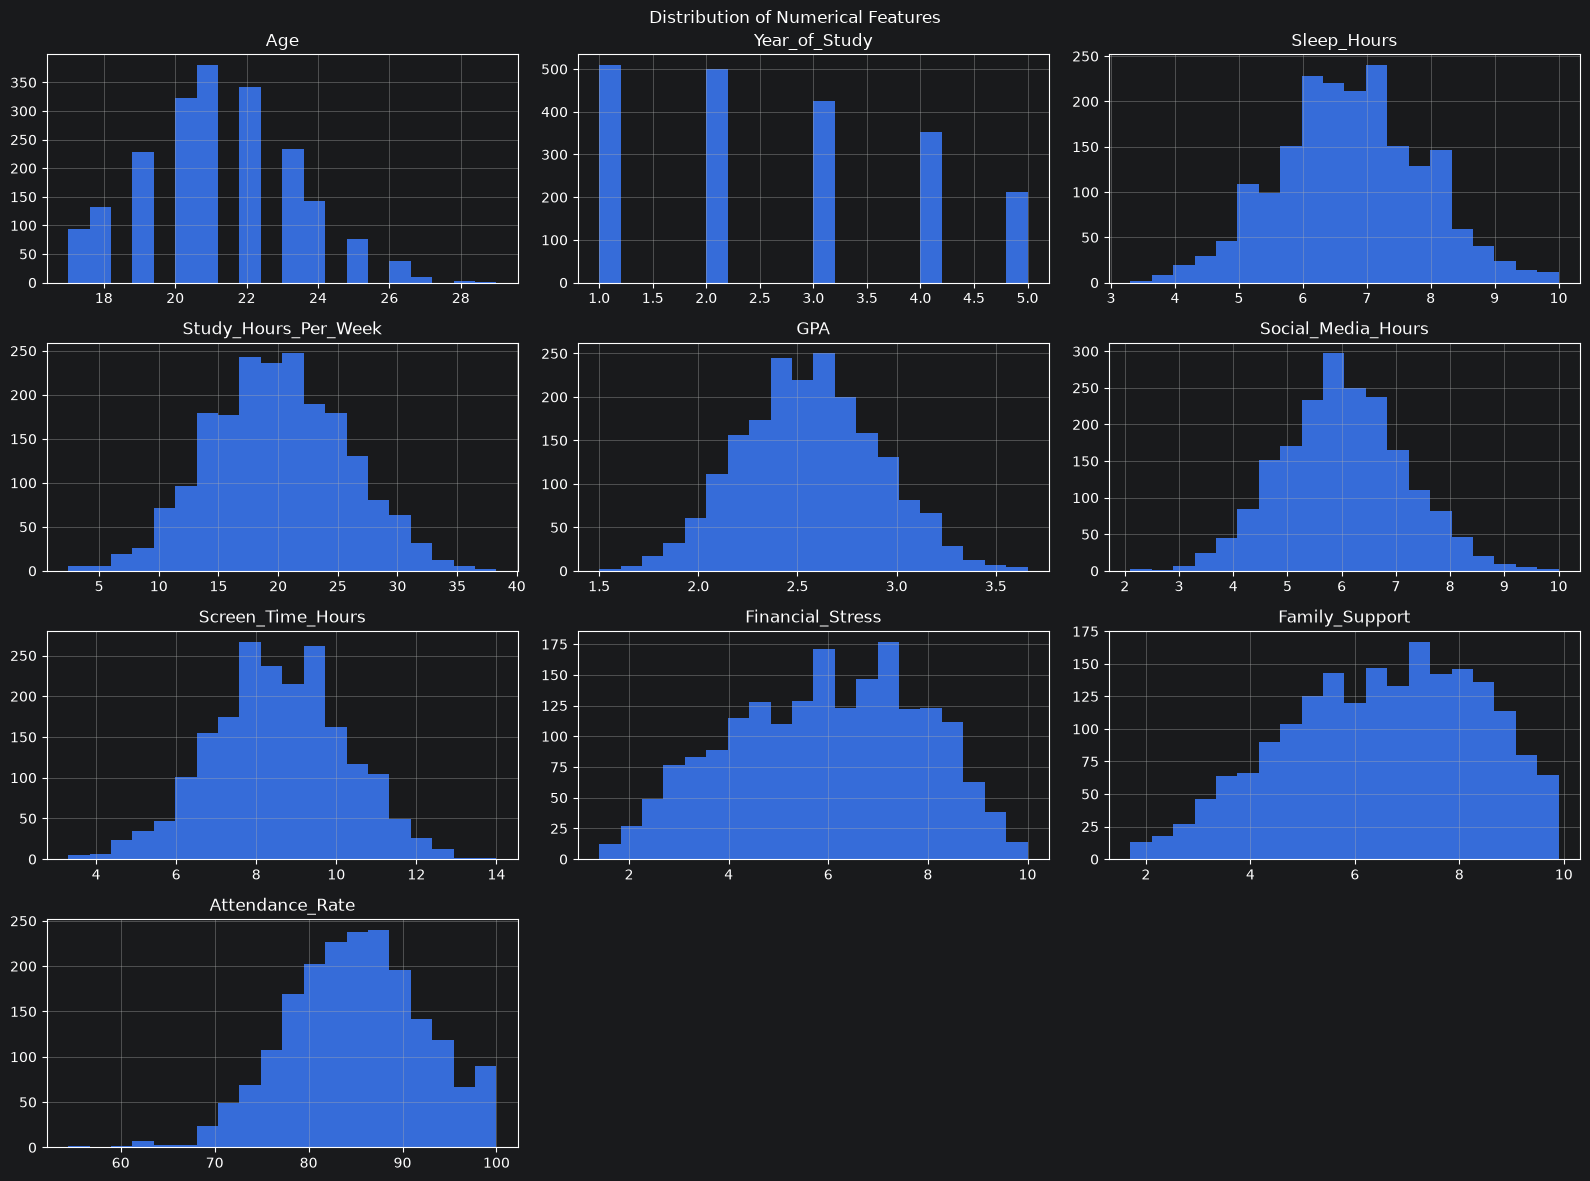

In [95]:
df[numerical_columns].hist(figsize=(16, 12),bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [96]:
display(df[df["Social_Media_Hours"] > df["Screen_Time_Hours"]])

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
78,STU0079,21,Male,2,5.3,17.0,2.54,5.0,4.9,Moderate,2.9,3.6,88.3,Yes,Good,Yes,High
168,STU0169,20,Female,3,6.2,25.7,2.47,5.6,5.3,Moderate,4.6,7.5,88.7,Yes,Average,Yes,Medium
209,STU0210,29,Female,4,6.5,22.1,3.02,7.5,7.3,Moderate,7.8,6.9,90.4,Yes,NaN,No,Low
278,STU0279,21,Female,3,6.7,17.9,2.54,6.0,5.1,High,6.5,7.6,81.3,No,Good,Yes,Medium
382,STU0383,17,Female,2,8.7,20.4,2.82,5.3,4.1,Low,3.8,8.8,90.5,Yes,Poor,Yes,Medium
424,STU0425,22,Female,3,8.6,20.9,2.27,5.5,4.4,Moderate,4.3,6.3,80.6,Yes,Average,No,Low
476,STU0477,22,Male,5,5.9,34.4,2.92,5.5,5.3,Moderate,2.4,3.8,91.5,Yes,Average,No,Low
505,STU0506,20,Male,1,5.2,17.7,2.46,5.6,5.5,Moderate,6.5,8.7,91.8,No,Good,No,Medium
557,STU0558,20,Male,1,6.3,17.7,2.45,4.6,4.4,Moderate,8.9,4.3,98.8,No,Poor,No,High
588,STU0589,23,Female,3,6.4,26.7,NaN,5.7,5.3,Moderate,7.3,8.5,87.3,No,Average,No,Low


In [97]:
id_columns = ["Student_ID"]

df = df.drop(columns=id_columns, errors="ignore")


In [98]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

/tmp/ipykernel_5420/1078726420.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


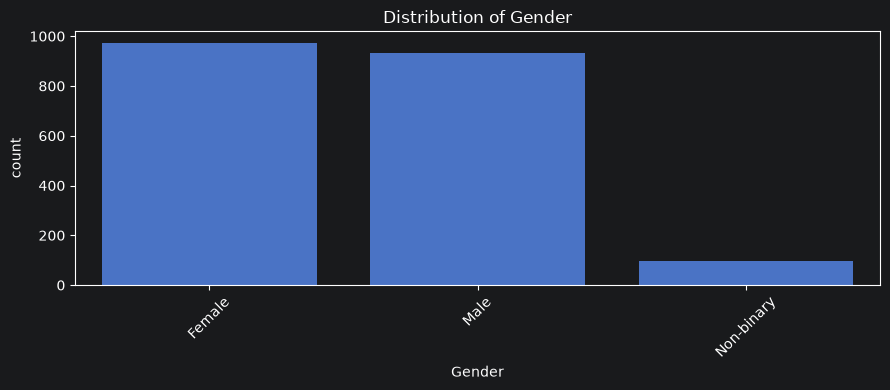

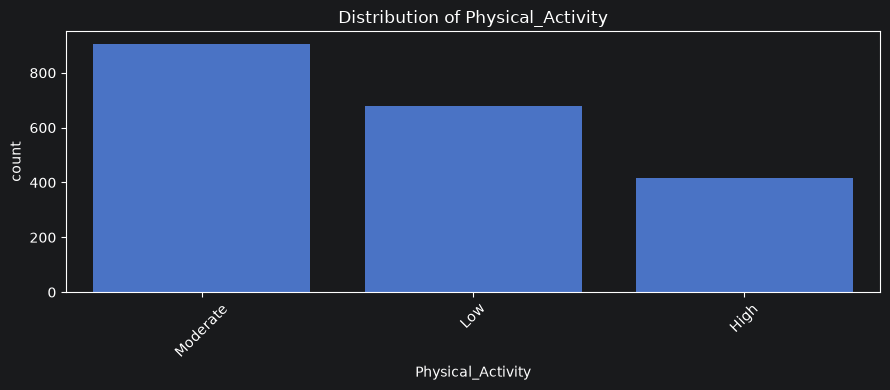

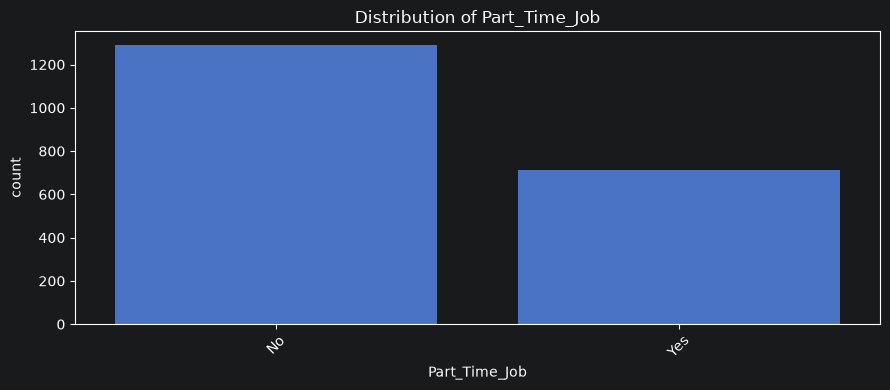

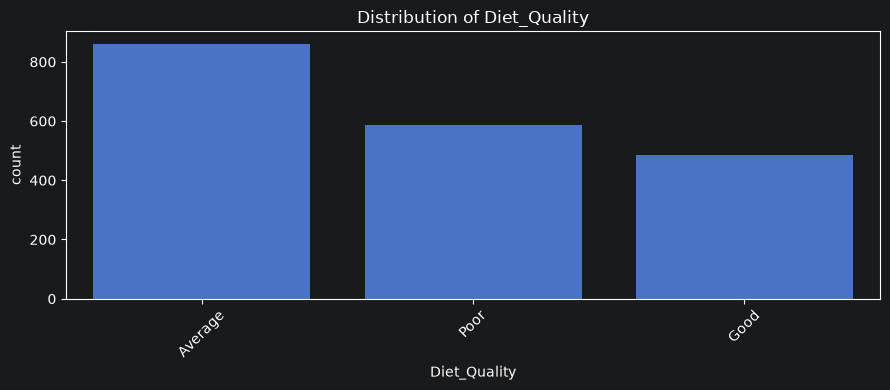

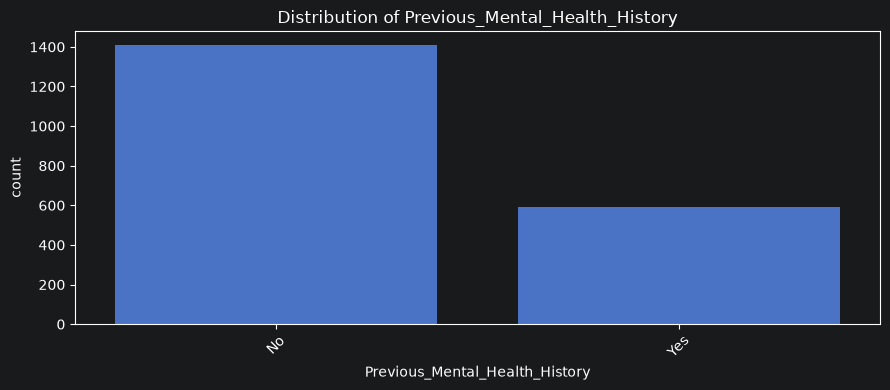

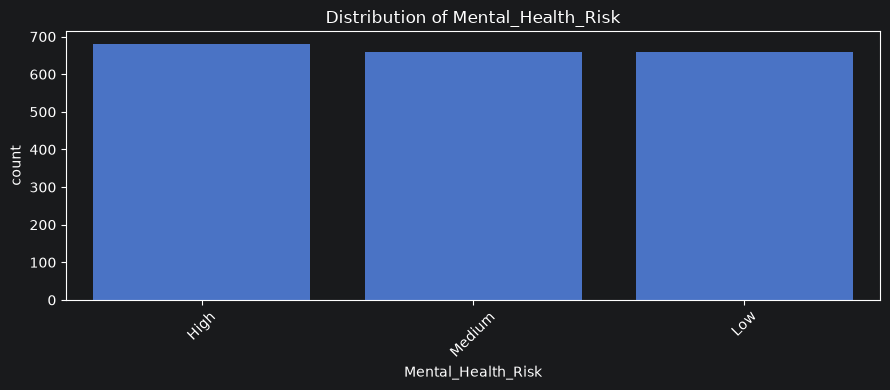

In [99]:

for col in categorical_columns:
    plt.figure(figsize=(9, 4))

    sns.countplot(data=df,x=col,order=df[col].value_counts().index)

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

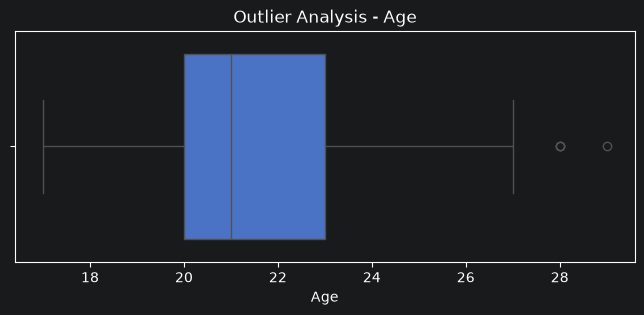

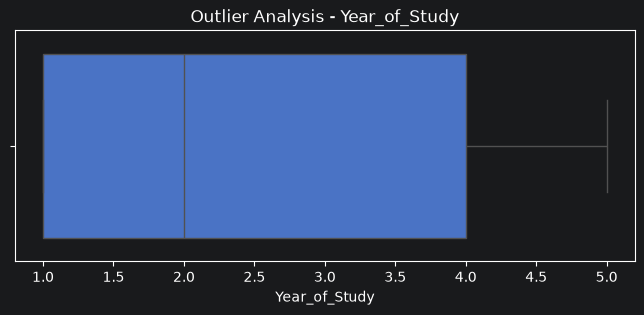

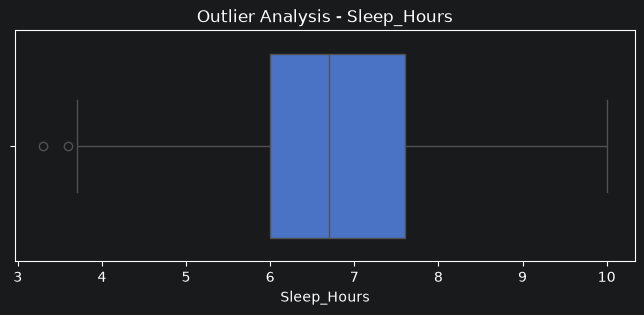

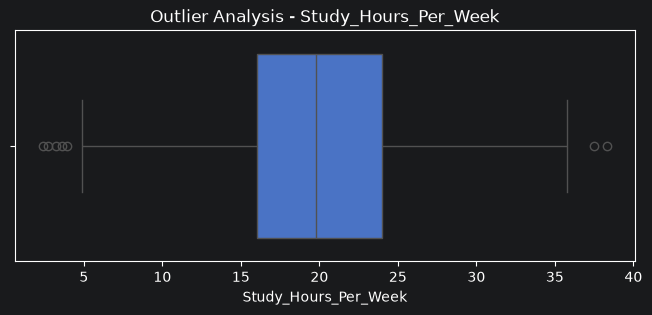

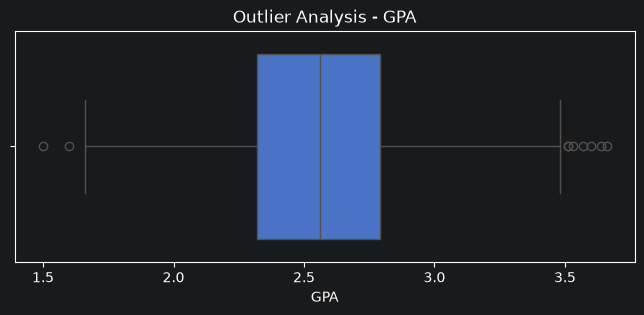

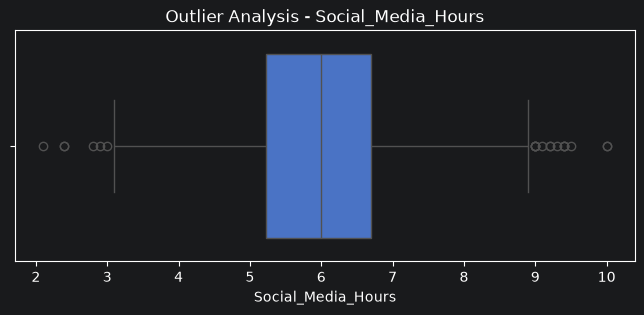

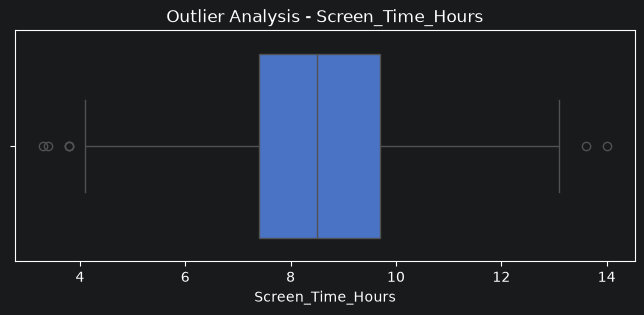

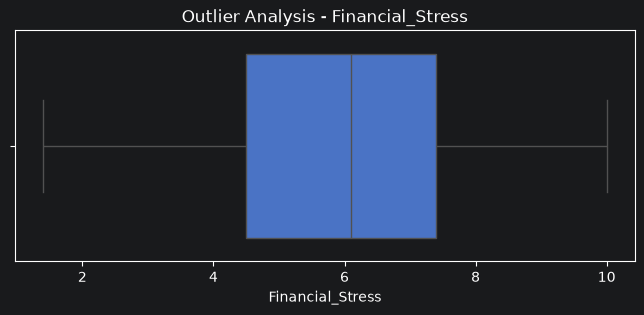

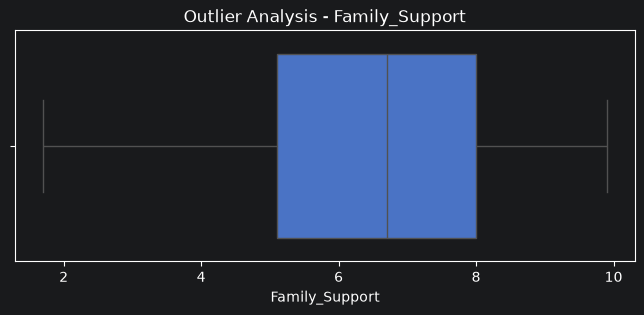

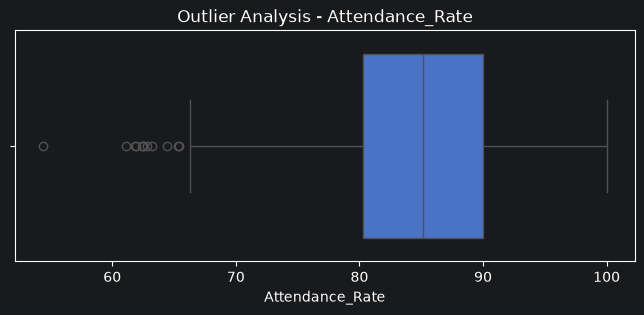

In [100]:
for col in numerical_columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Analysis - {col}")
    plt.show()

In [101]:
outlier_results = []

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Outliers": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df)

                Feature  Outliers  Percentage
0                   Age         4        0.20
1         Year_of_Study         0        0.00
2           Sleep_Hours         2        0.10
3  Study_Hours_Per_Week         7        0.35
4                   GPA         9        0.45
5    Social_Media_Hours        20        1.00
6     Screen_Time_Hours         7        0.35
7      Financial_Stress         0        0.00
8        Family_Support         0        0.00
9       Attendance_Rate        12        0.60


In [102]:
print(df.columns.tolist())

['Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


In [103]:
target_col = "Mental_Health_Risk"

In [104]:
print(df[target_col].value_counts())

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


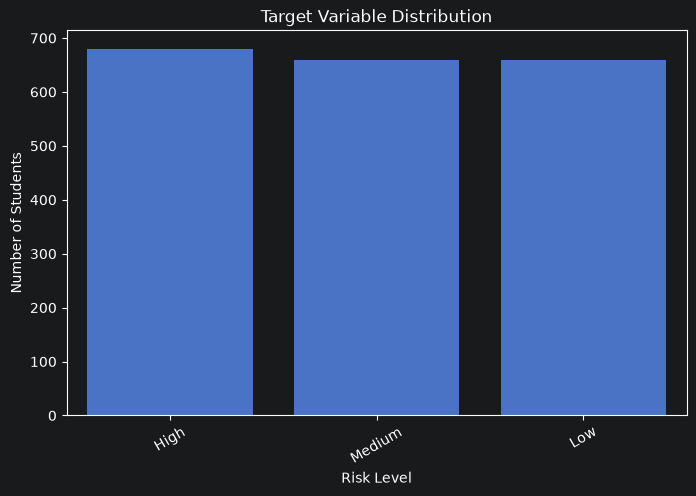

In [105]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=target_col, order=df[target_col].value_counts().index)

plt.title("Target Variable Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Students")
plt.xticks(rotation=30)
plt.show()

In [106]:
class_distribution = df[target_col].value_counts(normalize=True) * 100

print(class_distribution.round(2))

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


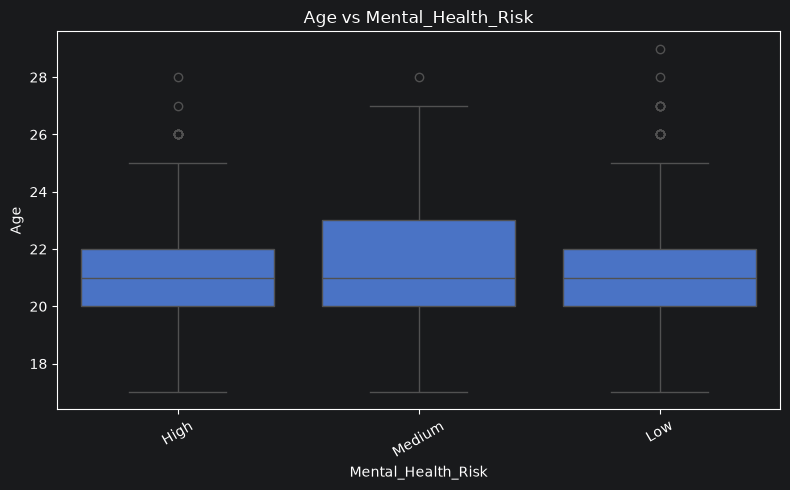

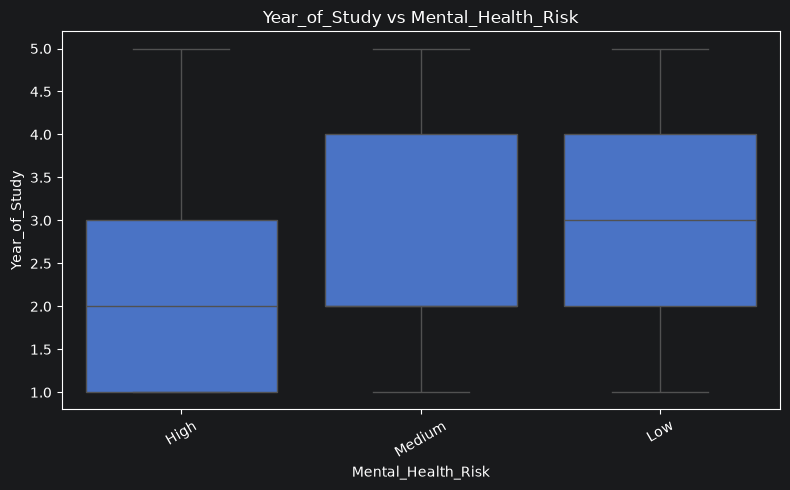

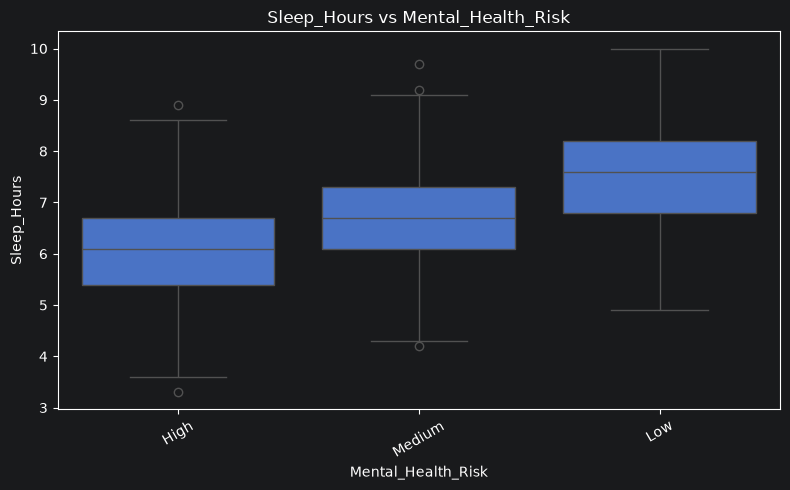

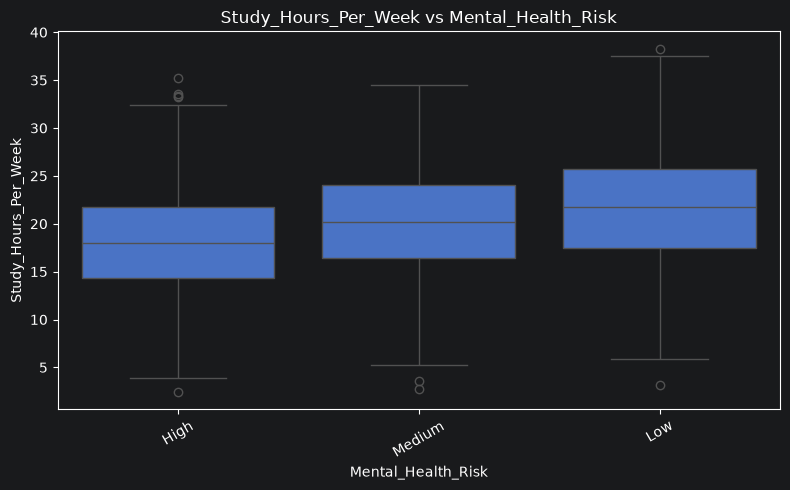

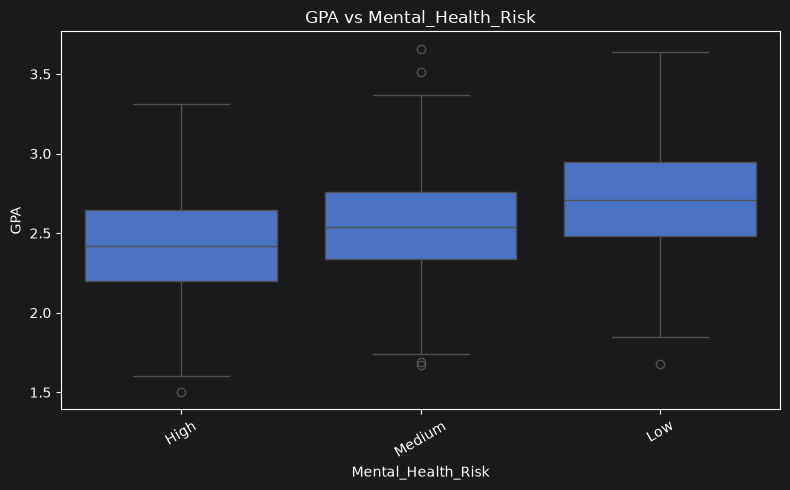

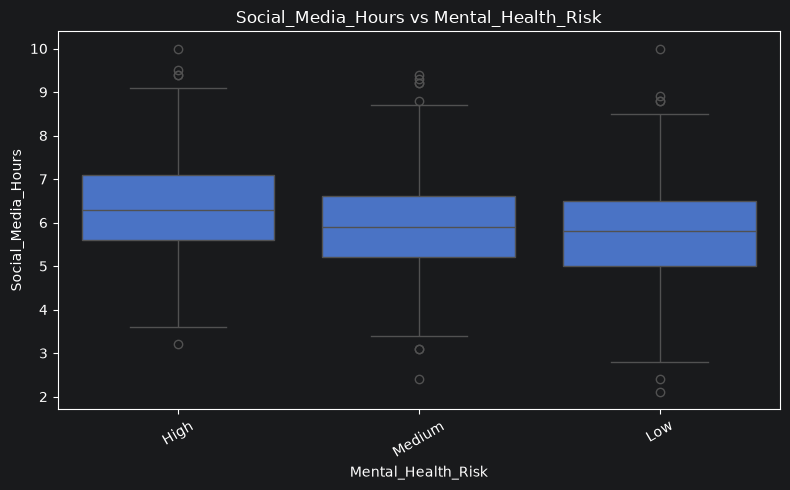

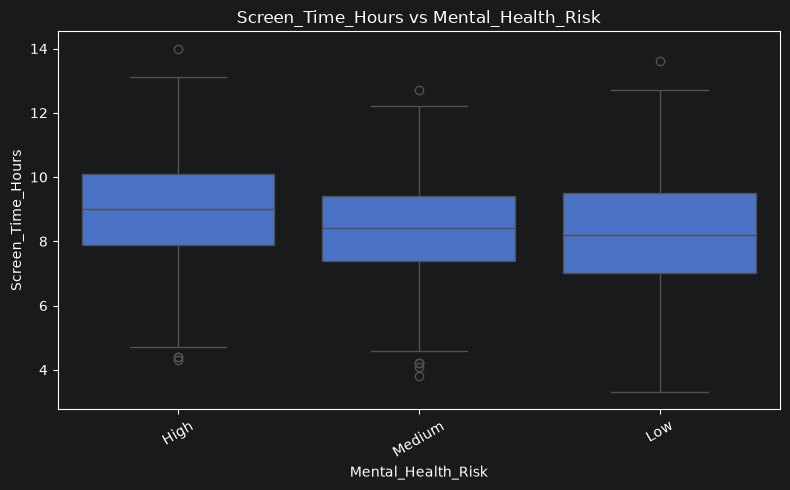

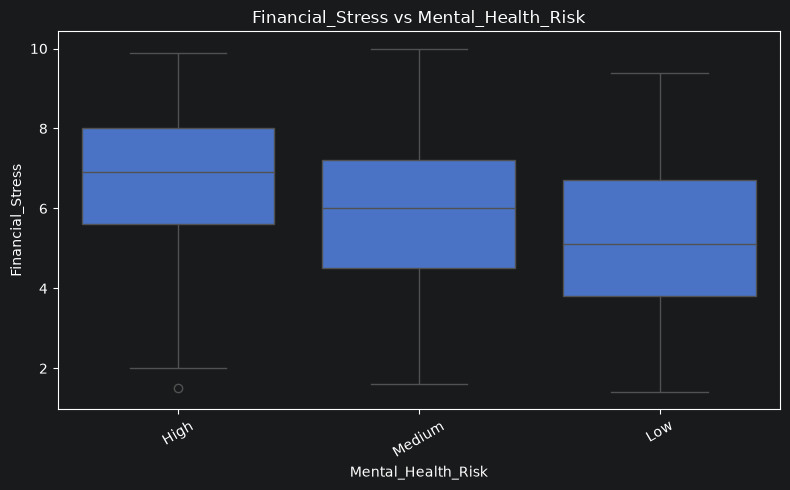

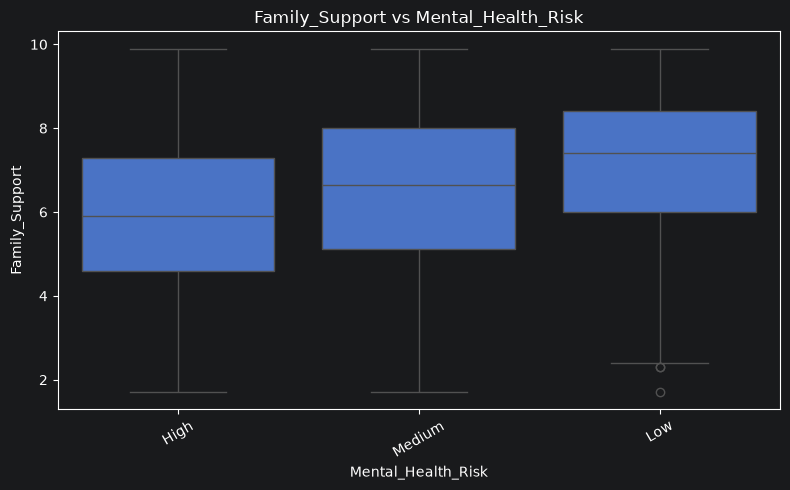

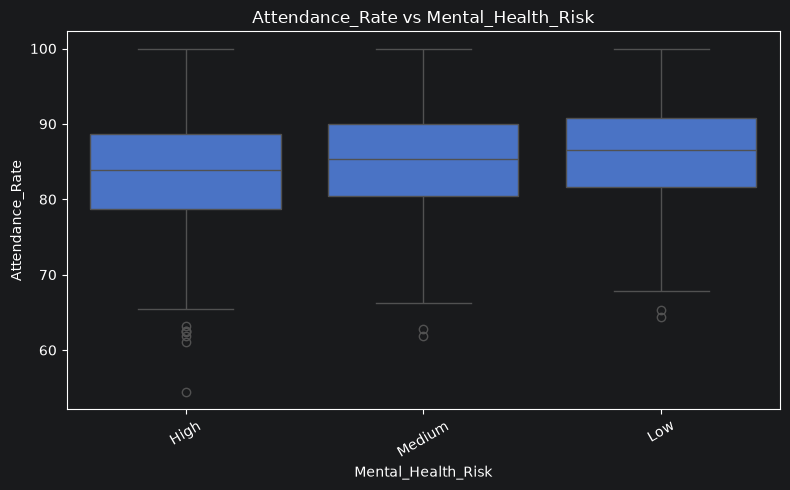

In [107]:
for col in numerical_columns:
    if col == target_col:
        continue

    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df,x=target_col,y=col)

    plt.title(f"{col} vs {target_col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

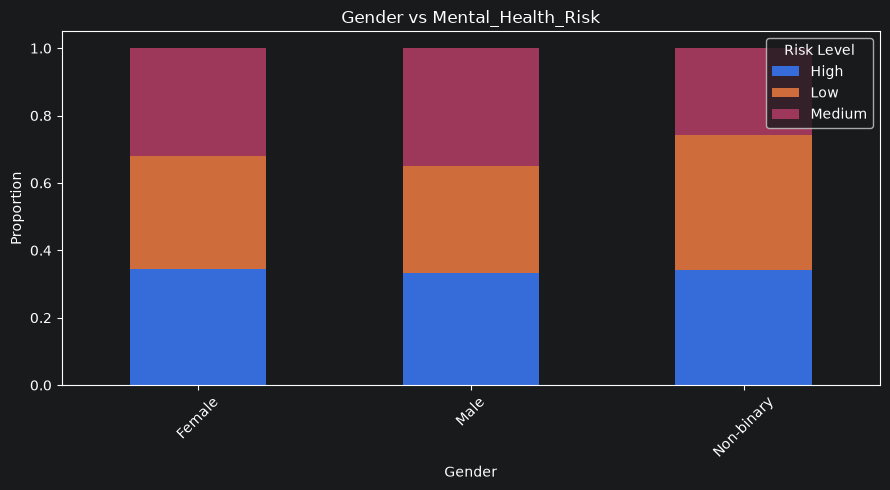

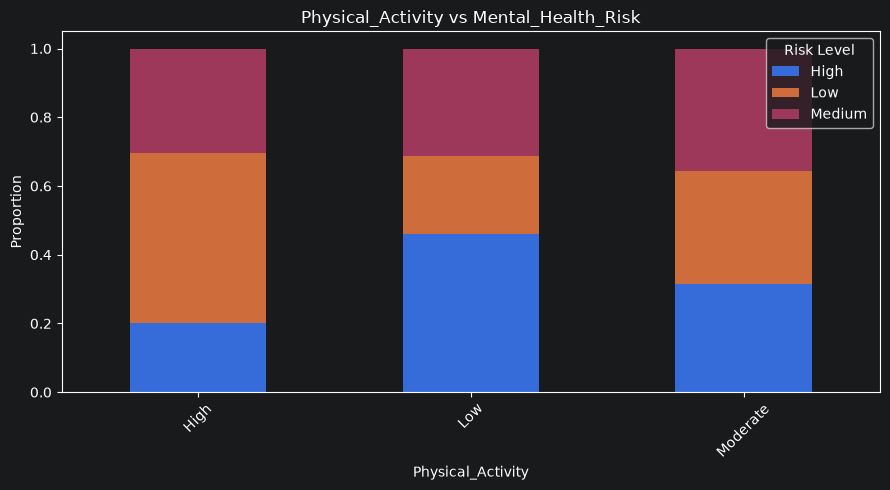

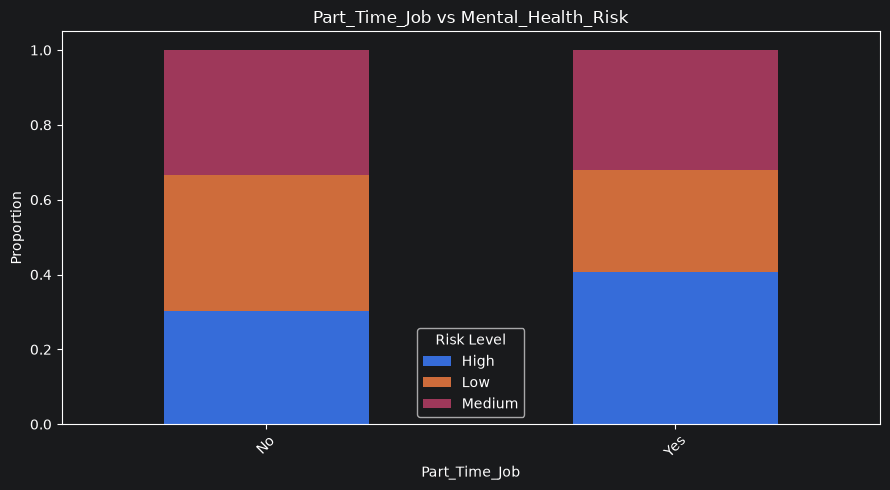

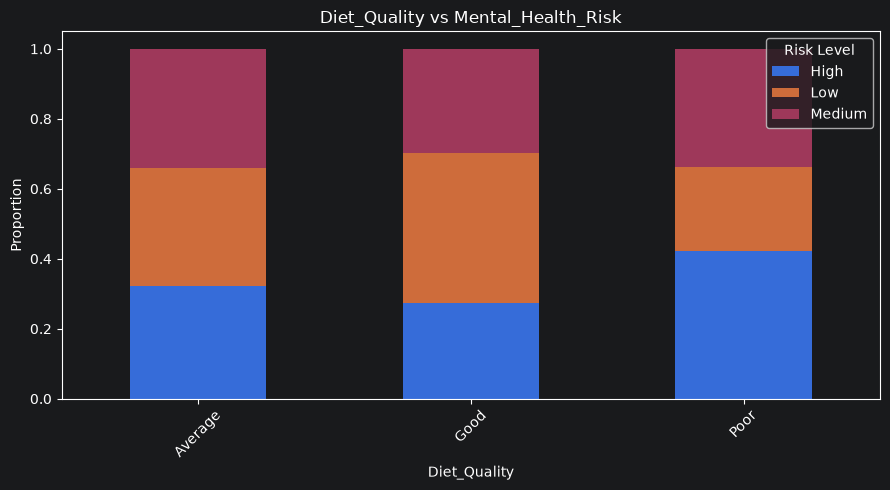

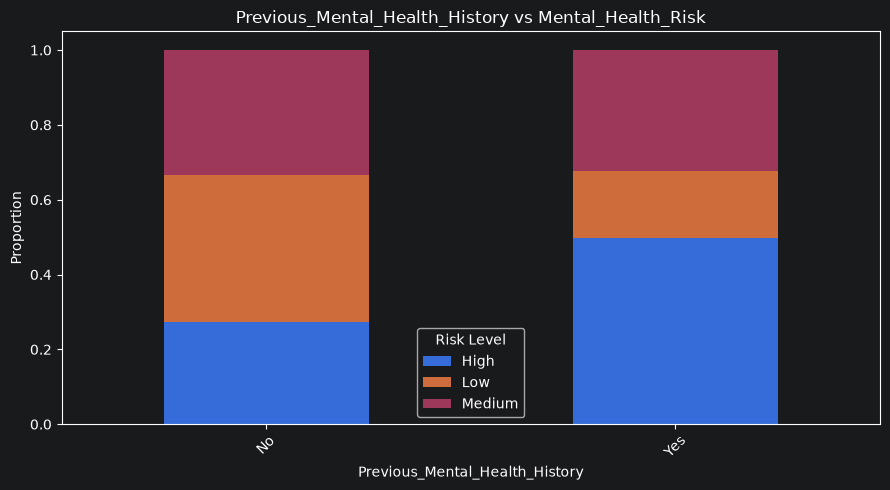

In [108]:
for col in categorical_columns:
    if col == target_col:
        continue

    proportions = pd.crosstab(df[col],df[target_col],normalize="index")

    proportions.plot(kind="bar",stacked=True,figsize=(9, 5))

    plt.title(f"{col} vs {target_col}")
    plt.xlabel(col)
    plt.ylabel("Proportion")
    plt.xticks(rotation=45)
    plt.legend(title="Risk Level")
    plt.tight_layout()
    plt.show()

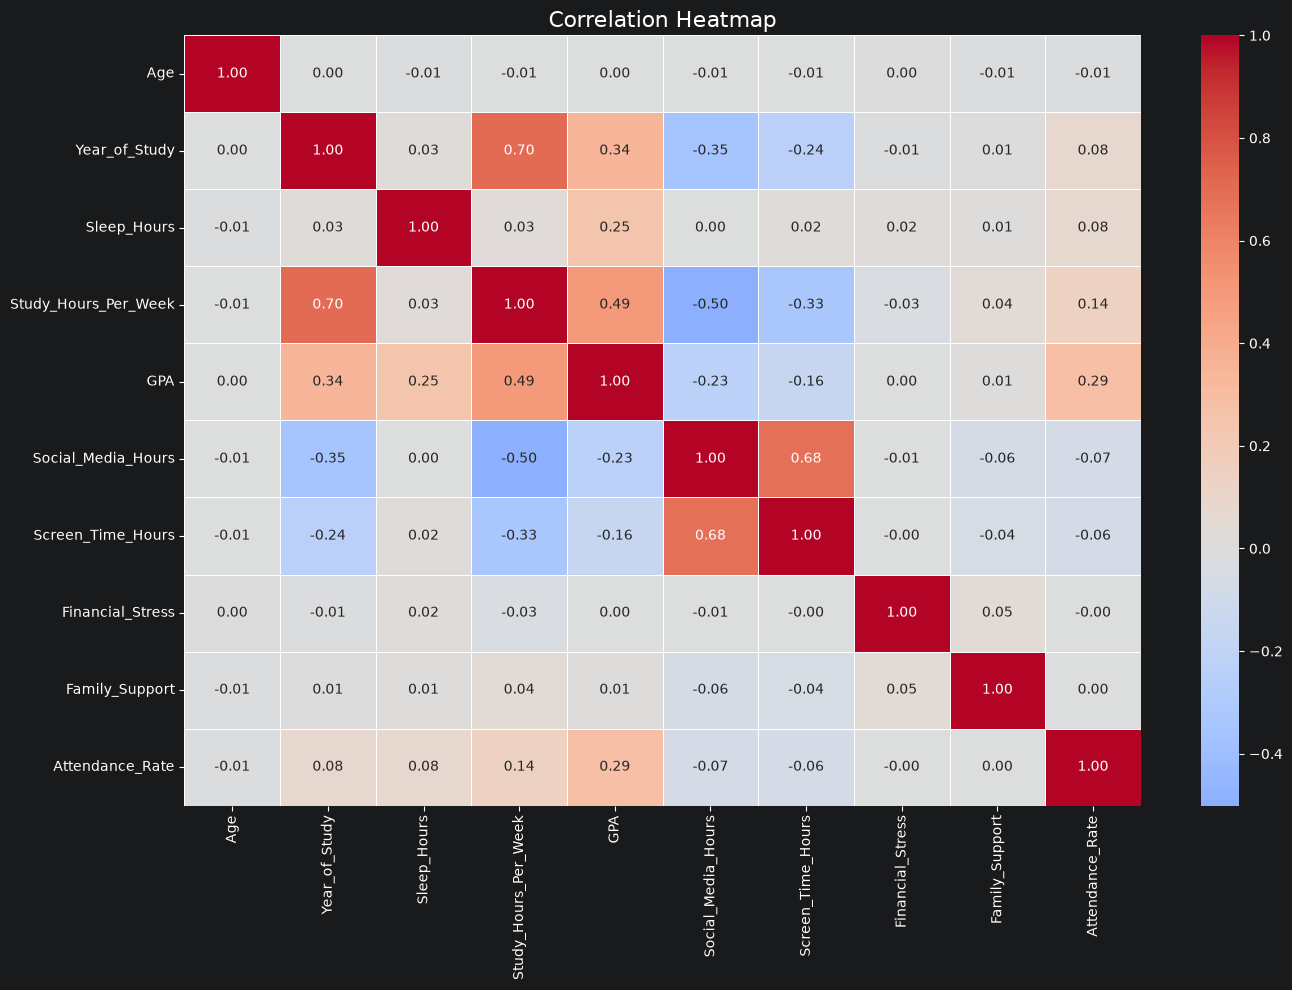

In [109]:
correlation_matrix = df[numerical_columns].corr(method="pearson")

plt.figure(figsize=(14, 10))

sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5,center=0)

plt.title("Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()